# COLAB notebook – Cluster E: Team 19 (CUDA) + Team 20 final analysis
**Run every cell of THIS notebook in Google Colab** (*Runtime → Change runtime type → T4 GPU*), top to bottom. Run the LOCAL notebook first – this one needs its results.

**What to upload to Colab:** only **`local_results.zip`** (made by the last cell of the LOCAL notebook). It contains
* `results/team17.csv` – CPU baseline, needed for the GPU-vs-CPU speedup (step D8),
* `results/team18*.csv` – not needed here, just kept together,
* `acc/` – the 9 CPU accuracy runs (`seq`, `openmp`, `mpi` × fp64/fp32/mixed: `*_energy.csv`, `*_traj.bin`, `*_results.csv`) – needed so the final comparison covers CPU **and** GPU.

| Part | What |
|---|---|
| A | setup, upload `local_results.zip`, shared header |
| D | Team 19: naive/tiled CUDA, tile sizes 64/128/256, rsqrt, unrolling, profile, speedup over CPU |
| E | Team 20: GPU accuracy runs (same N and steps as the local runs) + the final analysis of **all** platforms |

**Settings from the brief:** performance = 100 steps (fewer for the very large N – the interactions/s rate does not depend on the number of steps); accuracy = 10,000 steps, N = 4096 (same as local); GPU up to 1,048,576 particles; 20 flop per interaction.

☁️ **[RUN IN COLAB]**  **A1 – setup** (run once)

In [1]:
import os
os.makedirs('/content/nbody/results', exist_ok=True); os.chdir('/content/nbody')
os.environ['PATH'] += ':/usr/local/cuda/bin'
print('working dir:', os.getcwd())

working dir: /content/nbody


☁️ **[RUN IN COLAB]**  **A2 – check the GPU is there**

In [2]:
%%bash
nvcc --version | tail -1
nvidia-smi --query-gpu=name,compute_cap,memory.total --format=csv

Build cuda_13.0.r13.0/compiler.36424714_0
name, compute_cap, memory.total [MiB]
Tesla T4, 7.5, 15360 MiB


☁️ **[RUN IN COLAB]**  **A3 – upload `local_results.zip`** (a file-chooser button appears; pick the zip made on your PC). It is unpacked into `results/` and `acc/`.

In [17]:
from google.colab import files
import zipfile, glob, os, shutil
up = files.upload()                                     # choose local_results.zip
zipfile.ZipFile(list(up)[0]).extractall('.')
if os.path.isdir('nbody_work'):                         # the zip from your PC has a 'nbody_work/' prefix -> move its folders up
    for d in ('results', 'acc'):
        if os.path.isdir(f'nbody_work/{d}'): shutil.copytree(f'nbody_work/{d}', d, dirs_exist_ok=True)
if not os.path.exists('results/team17.csv') and os.path.exists('results/team17_corrected.csv'):
    shutil.copy('results/team17_corrected.csv', 'results/team17.csv')      # the name the later cells expect
print('team17.csv present:', os.path.exists('results/team17.csv'))
print('acc/ runs:', sorted({f.split("/")[-1].rsplit("_", 1)[0] for f in glob.glob("acc/*_energy.csv")}))

Saving local_results.zip to local_results (1).zip
team17.csv present: True
acc/ runs: ['mpi_fp32', 'mpi_fp64', 'mpi_mixed', 'openmp_fp32', 'openmp_fp64', 'openmp_mixed', 'seq_fp32', 'seq_fp64', 'seq_mixed']


☁️ **[RUN IN COLAB]**  **A4 – shared header** (identical to the local one)

In [18]:
%%writefile nbody_common.hpp
// =============================================================================
//  nbody_common.hpp  --  shared by Team 17 (OpenMP/Pthreads), Team 18 (MPI),
//  Team 19 (CUDA) and used by Team 20 (precision study).
//
//  EVERY platform uses exactly the same:
//    * physics   : softened gravity, G = 1, eps = 0.05, masses m_i = 1/N
//    * initial conditions : deterministic RNG (seed 42) -> identical on all platforms
//    * integrator: velocity-Verlet (kick-drift-kick), dt = 1e-3
//    * output    : results CSV (common course format), energy CSV, trajectory file
//
//  Precision modes (template "Mode" types):
//      fp64  : state S=double, pair-force arithmetic F=double
//      fp32  : state S=float , pair-force arithmetic F=float
//      mixed : state S=double, pair-force arithmetic F=float, accumulation in double
//              (dx = xj-xi is formed in double, THEN cast to float; the float pair
//               force is added to a double accumulator)
//  Diagnostics (energy, verification) are ALWAYS computed in FP64.
// =============================================================================
#pragma once
#include <cstdio>
#include <cstdlib>
#include <cstdint>
#include <cstring>
#include <cmath>
#include <vector>
#include <string>
#include <chrono>
#include <algorithm>

#if defined(__CUDACC__)
  #define NB_PRAGMA(x)
#else
  #define NB_PRAGMA(x) _Pragma(x)
#endif

namespace nb {

// ----------------------------- physics constants ----------------------------
constexpr double G    = 1.0;
constexpr double EPS2 = 0.05 * 0.05;   // softening length squared
constexpr double DT   = 1.0e-3;        // fixed time step
constexpr double V0   = 0.5;           // initial velocity half-range
constexpr uint64_t SEED = 42;

// ----------------------------- precision modes ------------------------------
struct M64  { typedef double S; typedef double F; static const char* name() { return "fp64";  } };
struct M32  { typedef float  S; typedef float  F; static const char* name() { return "fp32";  } };
struct MMix { typedef double S; typedef float  F; static const char* name() { return "mixed"; } };

inline std::string lower(std::string s) { for (auto& c : s) c = (char)tolower(c); return s; }

// ----------------------------- timing ---------------------------------------
inline double now_ms() {
    using namespace std::chrono;
    return duration<double, std::milli>(steady_clock::now().time_since_epoch()).count();
}

// ----------------------------- argument parsing -----------------------------
struct Args {
    std::vector<std::pair<std::string, std::string>> kv;
    Args(int argc, char** argv) {
        for (int i = 1; i < argc; ++i) {
            std::string k = argv[i];
            if (k.rfind("--", 0) == 0) {
                k = k.substr(2);
                std::string v = "1";
                if (i + 1 < argc && strncmp(argv[i + 1], "--", 2) != 0) v = argv[++i];
                kv.push_back({k, v});
            }
        }
    }
    bool has(const std::string& k) const { for (auto& p : kv) if (p.first == k) return true; return false; }
    std::string str(const std::string& k, const std::string& d) const { for (auto& p : kv) if (p.first == k) return p.second; return d; }
    int    i(const std::string& k, int d)    const { return has(k) ? atoi(str(k, "").c_str()) : d; }
    double d(const std::string& k, double dv) const { return has(k) ? atof(str(k, "").c_str()) : dv; }
};

// ----------------------------- initial conditions ---------------------------
struct Particles {
    int n = 0;
    std::vector<double> x, y, z, vx, vy, vz, m;
};

inline uint64_t splitmix64(uint64_t& s) {
    uint64_t z = (s += 0x9E3779B97F4A7C15ULL);
    z = (z ^ (z >> 30)) * 0xBF58476D1CE4E5B9ULL;
    z = (z ^ (z >> 27)) * 0x94D049BB133111EBULL;
    return z ^ (z >> 31);
}
inline double u01(uint64_t& s) { return (double)(splitmix64(s) >> 11) * (1.0 / 9007199254740992.0); }

// positions uniform in [-1,1]^3, velocities uniform in [-V0,V0]^3, m = 1/N.
inline Particles make_ic(int n, uint64_t seed = SEED) {
    Particles p; p.n = n;
    p.x.resize(n); p.y.resize(n); p.z.resize(n);
    p.vx.resize(n); p.vy.resize(n); p.vz.resize(n); p.m.assign(n, 1.0 / n);
    uint64_t s = seed;
    for (int i = 0; i < n; ++i) {
        p.x[i]  = 2.0 * u01(s) - 1.0;  p.y[i]  = 2.0 * u01(s) - 1.0;  p.z[i]  = 2.0 * u01(s) - 1.0;
        p.vx[i] = V0 * (2.0 * u01(s) - 1.0);
        p.vy[i] = V0 * (2.0 * u01(s) - 1.0);
        p.vz[i] = V0 * (2.0 * u01(s) - 1.0);
    }
    return p;
}

// ----------------------------- the force kernel (host) ----------------------
// Adds to (ax,ay,az) the acceleration on particle i (position xi,yi,zi) caused by
// the nj source particles xj,yj,zj,mj.  Self-interaction is harmless (dx=0).
template <class M>
inline void accel_one(typename M::S xi, typename M::S yi, typename M::S zi, int nj,
                      const typename M::S* xj, const typename M::S* yj, const typename M::S* zj,
                      const typename M::S* mj,
                      typename M::S& ax, typename M::S& ay, typename M::S& az) {
    typedef typename M::S S; typedef typename M::F F;
    S sx = 0, sy = 0, sz = 0;
    NB_PRAGMA("omp simd reduction(+:sx,sy,sz)")
    for (int j = 0; j < nj; ++j) {
        F dx = (F)(xj[j] - xi), dy = (F)(yj[j] - yi), dz = (F)(zj[j] - zi);
        F r2  = dx * dx + dy * dy + dz * dz + (F)EPS2;
        F inv = (F)1 / std::sqrt(r2);
        F s   = (F)mj[j] * (inv * inv * inv);
        sx += (S)(s * dx); sy += (S)(s * dy); sz += (S)(s * dz);
    }
    ax += sx; ay += sy; az += sz;
}

// ----------------------------- FP64 diagnostics -----------------------------
struct Energy { double ke, pe, etot; };

inline Energy energy(const Particles& p) {
    const int n = p.n;
    double ke = 0, pe = 0;
    for (int i = 0; i < n; ++i) ke += 0.5 * p.m[i] * (p.vx[i]*p.vx[i] + p.vy[i]*p.vy[i] + p.vz[i]*p.vz[i]);
    for (int i = 0; i < n; ++i) {
        double s = 0;
        NB_PRAGMA("omp simd reduction(+:s)")
        for (int j = i + 1; j < n; ++j) {
            double dx = p.x[j]-p.x[i], dy = p.y[j]-p.y[i], dz = p.z[j]-p.z[i];
            s += p.m[j] / std::sqrt(dx*dx + dy*dy + dz*dz + EPS2);
        }
        pe -= G * p.m[i] * s;
    }
    return {ke, pe, ke + pe};
}

// Reference accelerations: sequential, FP64.
inline void ref_accel(const Particles& p, std::vector<double>& ax, std::vector<double>& ay, std::vector<double>& az) {
    const int n = p.n;
    ax.assign(n, 0); ay.assign(n, 0); az.assign(n, 0);
    for (int i = 0; i < n; ++i)
        accel_one<M64>(p.x[i], p.y[i], p.z[i], n, p.x.data(), p.y.data(), p.z.data(), p.m.data(), ax[i], ay[i], az[i]);
}

// max over particles of |a - a_ref| / |a_ref|
inline double max_rel_force_error(const std::vector<double>& ax, const std::vector<double>& ay, const std::vector<double>& az,
                                  const std::vector<double>& rx, const std::vector<double>& ry, const std::vector<double>& rz) {
    double worst = 0;
    for (size_t i = 0; i < ax.size(); ++i) {
        double ex = ax[i]-rx[i], ey = ay[i]-ry[i], ez = az[i]-rz[i];
        double num = std::sqrt(ex*ex + ey*ey + ez*ez);
        double den = std::sqrt(rx[i]*rx[i] + ry[i]*ry[i] + rz[i]*rz[i]);
        worst = std::max(worst, num / (den > 0 ? den : 1.0));
    }
    return worst;
}

// ----------------------------- results CSV (course format) ------------------
inline void csv_row(const std::string& path, int problem, const std::string& platform, const std::string& impl,
                    const std::string& dataset, int size, int par, int run_id,
                    double total_ms, double kernel_ms, double transfer_ms, double thr, double err) {
    bool exists = false;
    if (FILE* t = fopen(path.c_str(), "r")) { fseek(t, 0, SEEK_END); exists = ftell(t) > 0; fclose(t); }
    FILE* f = fopen(path.c_str(), "a");
    if (!f) { fprintf(stderr, "cannot open %s\n", path.c_str()); return; }
    if (!exists) fprintf(f, "cluster,problem,platform,implementation,dataset,size,threads_or_ranks,run_id,total_ms,kernel_ms,transfer_ms,throughput,error,power_w\n");
    char e[64] = ""; if (err >= 0) snprintf(e, sizeof e, "%.3e", err);
    fprintf(f, "E,%d,%s,%s,%s,%d,%d,%d,%.6f,%.6f,%.6f,%.6e,%s,\n", problem, platform.c_str(), impl.c_str(),
            dataset.c_str(), size, par, run_id, total_ms, kernel_ms, transfer_ms, thr, e);
    fclose(f);
}

// ----------------------------- the driver -----------------------------------
// A "Sim" backend must provide:
//   bool is_root(); std::string impl(); int par();
//   void load(const Particles&);      // set state + compute initial accelerations, reset timers
//   void advance(int steps);          // velocity-Verlet steps
//   void sync(); void finalize();     // barrier / copy-back (finalize = timed D2H for GPU)
//   Timing timing();                  // kernel_ms<0 means "same as step wall time"
//   bool gather(Particles&);          // full FP64 state on root (returns true on root)
//   bool gather_accel(vector<double>&,vector<double>&,vector<double>&);
//   std::string notes();
struct Timing { double kernel_ms = -1, transfer_ms = 0, extra_ms = 0; };

template <class Sim>
int drive(Sim& sim, const Args& a, int problem, const std::string& platform, const char* prec_name) {
    const int n = a.i("n", 4096), steps = a.i("steps", 100), runs = a.i("runs", 5);
    const int eevery = a.i("energy-every", 0);
    const std::string csv = a.str("csv", "results.csv"), out = a.str("out", "run");
    const bool root = sim.is_root();
    const std::string impl = sim.impl();
    Particles ic = make_ic(n);

    // ---- first-step verification against the sequential FP64 reference ----
    double err = -1;
    if (a.i("verify", 1) && n <= a.i("verify-max", 65536)) {
        sim.load(ic);
        std::vector<double> ax, ay, az;
        bool r = sim.gather_accel(ax, ay, az);
        if (r) {
            std::vector<double> rx, ry, rz; ref_accel(ic, rx, ry, rz);
            err = max_rel_force_error(ax, ay, az, rx, ry, rz);
            printf("VERIFY  impl=%s  N=%d  max_rel_force_error_vs_seq_fp64 = %.3e\n", impl.c_str(), n, err);
        }
    }

    if (eevery <= 0) {
        // ------------------------- performance mode -------------------------
        std::vector<double> tot, thr;
        for (int r = 0; r <= runs; ++r) {            // r = 0 is the warm-up run (discarded)
            sim.load(ic); sim.sync();
            double t0 = now_ms();
            sim.advance(steps);
            sim.sync();
            double step_ms = now_ms() - t0;
            sim.finalize();
            Timing t = sim.timing();
            double total = step_ms + t.extra_ms;
            double kern  = t.kernel_ms >= 0 ? t.kernel_ms : step_ms - t.transfer_ms;
            double ips   = (double)n * n * steps / (step_ms * 1e-3);   // N^2 pair interactions / s
            if (r > 0 && root) {
                csv_row(csv, problem, platform, impl, "gravity_steps" + std::to_string(steps), n, sim.par(), r, total, kern, t.transfer_ms, ips, err);
                tot.push_back(total); thr.push_back(ips);
            }
        }
        if (root) {
            double mt = 0, mi = 0; for (double v : tot) mt += v; for (double v : thr) mi += v;
            mt /= tot.size(); mi /= thr.size();
            double st = 0, si = 0; for (double v : tot) st += (v-mt)*(v-mt); for (double v : thr) si += (v-mi)*(v-mi);
            st = std::sqrt(st / std::max<size_t>(1, tot.size()-1)); si = std::sqrt(si / std::max<size_t>(1, thr.size()-1));
            printf("RESULT  %-28s N=%-7d steps=%-5d par=%-3d total_ms=%.2f+-%.2f  Ginteractions/s=%.4f+-%.4f  GFLOP/s(20 flop/int)=%.2f  [%d timed runs]\n",
                   impl.c_str(), n, steps, sim.par(), mt, st, mi/1e9, si/1e9, 20.0*mi/1e9, (int)tot.size());
            std::string nt = sim.notes(); if (!nt.empty()) printf("NOTES   %s\n", nt.c_str());
            printf("CSV rows appended to %s\n", csv.c_str());
        }
        return 0;
    }

    // ------------------------- accuracy / energy mode -----------------------
    sim.load(ic);
    FILE* fe = nullptr; std::vector<double> snaps; int nsnap = 0; double E0 = 0, maxdrift = 0, adv_ms = 0;
    if (root) { fe = fopen((out + "_energy.csv").c_str(), "w"); fprintf(fe, "step,time,ke,pe,etot,rel_drift\n"); }
    auto sample = [&](int step) {
        Particles s; if (!sim.gather(s)) return;
        Energy e = energy(s);
        if (step == 0) E0 = e.etot;
        double drift = (e.etot - E0) / std::fabs(E0); maxdrift = std::max(maxdrift, std::fabs(drift));
        fprintf(fe, "%d,%.9g,%.17g,%.17g,%.17g,%.6e\n", step, step * DT, e.ke, e.pe, e.etot, drift);
        snaps.insert(snaps.end(), s.x.begin(), s.x.end());
        snaps.insert(snaps.end(), s.y.begin(), s.y.end());
        snaps.insert(snaps.end(), s.z.begin(), s.z.end());
        ++nsnap;
    };
    sample(0);
    for (int s = 0; s < steps; s += eevery) {
        int k = std::min(eevery, steps - s);
        sim.sync(); double t0 = now_ms();
        sim.advance(k);
        sim.sync(); adv_ms += now_ms() - t0;
        sample(s + k);
    }
    if (root) {
        fclose(fe);
        FILE* ft = fopen((out + "_traj.bin").c_str(), "wb");      // header: int64 n, int64 nsnap; then nsnap*(x[n],y[n],z[n]) doubles
        int64_t h[2] = {n, nsnap}; fwrite(h, sizeof(int64_t), 2, ft);
        fwrite(snaps.data(), sizeof(double), snaps.size(), ft); fclose(ft);
        double ips = (double)n * n * steps / (adv_ms * 1e-3);
        csv_row(csv, problem, platform, impl, "accuracy_steps" + std::to_string(steps), n, sim.par(), 1, adv_ms, adv_ms, 0, ips, err);
        printf("ACCURACY impl=%s N=%d steps=%d  advance_time=%.1f ms  Ginteractions/s=%.4f  max|dE/E0|=%.3e\n",
               impl.c_str(), n, steps, adv_ms, ips / 1e9, maxdrift);
        printf("wrote %s_energy.csv and %s_traj.bin\n", out.c_str(), out.c_str());
    }
    (void)prec_name;
    return 0;
}

}  // namespace nb

Overwriting nbody_common.hpp


☁️ **[RUN IN COLAB]**

## Part D – Team 19 · Problem 19 · CUDA N-body  *(needs the GPU runtime)*
**Variants:** `naive` (one thread/particle, all reads from global memory) · `tiled` (shared-memory tiles, `--block` = 64/128/256).
Options: `--fast 1` uses `rsqrtf/rsqrt` (fast reciprocal sqrt), `--profile 1` prints registers/thread, shared memory and theoretical occupancy; rebuild with `-DUNROLL=1/4/8` for the unrolling study. FLOP convention: **20 flop per interaction**.
`threads_or_ranks` column = thread-block size; `transfer_ms` = host↔device copies. Not included: the *optional* cell-list Lennard-Jones code.

Steps: **D1** code → **D2** compile → **D3** verify → **D4** tile-size sweep → **D5** fast-rsqrt accuracy/speed → **D6** unrolling → **D7** (optional) Nsight → **D8** speedup over CPU.

☁️ **[RUN IN COLAB]**  **D1 – source code**

In [20]:
%%writefile nbody_cuda.cu
// =============================================================================
//  Team 19 / Problem 19 : CUDA N-body
//
//  variants (--variant):
//    naive   one thread per particle, every position read from global memory
//    tiled   shared-memory tiling; tile (= thread block) size --block 64|128|256
//  options:
//    --fast 0|1     0: 1/sqrt(r2) computed with IEEE sqrt + divide   1: rsqrtf()/rsqrt() fast reciprocal sqrt
//    --block B      thread-block size (tiled: 64/128/256; naive: any, default 128)
//    --profile 1    print registers/thread, shared memory, occupancy of the force kernel
//    -DUNROLL=k     (compile time) inner-loop unroll factor, default 4 -> rebuild with 1, 4, 8 to study unrolling
//  precision (--prec): fp64 | fp32 | mixed   (same definitions as the CPU codes)
//
//  FLOP convention: 20 floating-point operations per pair interaction (GPU Gems 3, ch. 31).
//  CSV columns: kernel_ms = CUDA-event time of all steps, transfer_ms = H2D + D2H (wall clock), total = kernel + transfer
// =============================================================================
#include "nbody_common.hpp"
#include <cuda_runtime.h>

#ifndef UNROLL
#define UNROLL 4
#endif
constexpr int UNR = UNROLL;      // nvcc does not expand macros inside "#pragma unroll", so use a constexpr

using namespace nb;

#define CK(call) do { cudaError_t e_ = (call); if (e_ != cudaSuccess) { \
    fprintf(stderr, "CUDA error %s at %s:%d : %s\n", #call, __FILE__, __LINE__, cudaGetErrorString(e_)); exit(1); } } while (0)

// ---------------- device helpers ----------------
template <bool FAST> __device__ __forceinline__ float  invs(float v)  { return FAST ? rsqrtf(v) : 1.0f / sqrtf(v); }
template <bool FAST> __device__ __forceinline__ double invs(double v) { return FAST ? rsqrt(v)  : 1.0  / sqrt(v);  }

// ---------------- kernels ----------------
// Naive: thread i loops over ALL N particles, reading global memory.
template <class S, class F, bool FAST>
__global__ void accel_naive(int N, const S* __restrict__ x, const S* __restrict__ y, const S* __restrict__ z,
                            const S* __restrict__ m, S* __restrict__ ax, S* __restrict__ ay, S* __restrict__ az) {
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i >= N) return;
    const S xi = x[i], yi = y[i], zi = z[i];
    S sx = 0, sy = 0, sz = 0;
    #pragma unroll UNR
    for (int j = 0; j < N; ++j) {
        F dx = (F)(x[j] - xi), dy = (F)(y[j] - yi), dz = (F)(z[j] - zi);
        F r2  = dx * dx + dy * dy + dz * dz + (F)EPS2;
        F inv = invs<FAST>(r2);
        F s   = (F)m[j] * (inv * inv * inv);
        sx += (S)(s * dx); sy += (S)(s * dy); sz += (S)(s * dz);
    }
    ax[i] = sx; ay[i] = sy; az[i] = sz;
}

// Tiled: arrays are padded to Npad (a multiple of BS) with mass-0 particles, so every thread
// takes part in every tile load and __syncthreads() (padding particles exert exactly zero force).
template <class S, class F, int BS, bool FAST>
__global__ void accel_tiled(int N, int Npad, const S* __restrict__ x, const S* __restrict__ y, const S* __restrict__ z,
                            const S* __restrict__ m, S* __restrict__ ax, S* __restrict__ ay, S* __restrict__ az) {
    __shared__ S sx_[BS], sy_[BS], sz_[BS], sm_[BS];
    const int tid = threadIdx.x;
    const int i = blockIdx.x * BS + tid;                 // always < Npad
    const S xi = x[i], yi = y[i], zi = z[i];
    S sx = 0, sy = 0, sz = 0;
    for (int tile = 0; tile < Npad; tile += BS) {
        sx_[tid] = x[tile + tid]; sy_[tid] = y[tile + tid]; sz_[tid] = z[tile + tid]; sm_[tid] = m[tile + tid];
        __syncthreads();
        #pragma unroll UNR
        for (int j = 0; j < BS; ++j) {
            F dx = (F)(sx_[j] - xi), dy = (F)(sy_[j] - yi), dz = (F)(sz_[j] - zi);
            F r2  = dx * dx + dy * dy + dz * dz + (F)EPS2;
            F inv = invs<FAST>(r2);
            F s   = (F)sm_[j] * (inv * inv * inv);
            sx += (S)(s * dx); sy += (S)(s * dy); sz += (S)(s * dz);
        }
        __syncthreads();
    }
    if (i < N) { ax[i] = sx; ay[i] = sy; az[i] = sz; }
}

template <class S>
__global__ void kick_drift(int N, S dt, S hdt, S* x, S* y, S* z, S* vx, S* vy, S* vz,
                           const S* ax, const S* ay, const S* az) {
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i >= N) return;
    vx[i] += hdt * ax[i]; vy[i] += hdt * ay[i]; vz[i] += hdt * az[i];
    x[i] += dt * vx[i];   y[i] += dt * vy[i];   z[i] += dt * vz[i];
}
template <class S>
__global__ void kick(int N, S hdt, S* vx, S* vy, S* vz, const S* ax, const S* ay, const S* az) {
    int i = blockIdx.x * blockDim.x + threadIdx.x;
    if (i >= N) return;
    vx[i] += hdt * ax[i]; vy[i] += hdt * ay[i]; vz[i] += hdt * az[i];
}

// ---------------- host backend ----------------
template <class M>
struct CudaSim {
    typedef typename M::S S; typedef typename M::F F;
    int N, Npad, BS; bool tiled, fast;
    S *dx = 0, *dy = 0, *dz = 0, *dvx = 0, *dvy = 0, *dvz = 0, *dm = 0, *dax = 0, *day = 0, *daz = 0;
    cudaEvent_t e0, e1;
    double t_kernel = 0, t_h2d = 0, t_d2h = 0;
    std::vector<double> md;
    std::string variant; int fastflag;

    CudaSim(int N_, const std::string& v, int block, int fast_) : N(N_), BS(block), variant(v), fastflag(fast_) {
        if (v != "naive" && v != "tiled") { fprintf(stderr, "variant must be naive or tiled\n"); exit(1); }
        tiled = (v == "tiled"); fast = fast_ != 0;
        if (tiled && BS != 64 && BS != 128 && BS != 256) { fprintf(stderr, "--block must be 64, 128 or 256 for the tiled kernel\n"); exit(1); }
        if (BS < 32 || BS > 1024) { fprintf(stderr, "--block out of range\n"); exit(1); }
        Npad = ((N + BS - 1) / BS) * BS;
        size_t b = (size_t)Npad * sizeof(S);
        CK(cudaMalloc(&dx, b));  CK(cudaMalloc(&dy, b));  CK(cudaMalloc(&dz, b));
        CK(cudaMalloc(&dvx, b)); CK(cudaMalloc(&dvy, b)); CK(cudaMalloc(&dvz, b));
        CK(cudaMalloc(&dm, b));  CK(cudaMalloc(&dax, b)); CK(cudaMalloc(&day, b)); CK(cudaMalloc(&daz, b));
        CK(cudaMemset(dax, 0, b)); CK(cudaMemset(day, 0, b)); CK(cudaMemset(daz, 0, b));
        CK(cudaEventCreate(&e0)); CK(cudaEventCreate(&e1));
    }
    ~CudaSim() {
        cudaFree(dx); cudaFree(dy); cudaFree(dz); cudaFree(dvx); cudaFree(dvy); cudaFree(dvz);
        cudaFree(dm); cudaFree(dax); cudaFree(day); cudaFree(daz);
        cudaEventDestroy(e0); cudaEventDestroy(e1);
    }
    bool is_root() const { return true; }
    std::string impl() const {
        return "cuda_" + variant + "_bs" + std::to_string(BS) + (fast ? "_rsqrt" : "_ieee") + "_u" + std::to_string(UNROLL) + "_" + M::name();
    }
    int par() const { return BS; }               // "threads_or_ranks" column = thread-block size for the GPU code
    std::string notes() { return "threads_or_ranks column holds the CUDA thread-block size; transfer_ms = H2D + D2H copies"; }
    void sync() { CK(cudaDeviceSynchronize()); }
    Timing timing() { Timing t; t.kernel_ms = t_kernel; t.transfer_ms = t_h2d + t_d2h; t.extra_ms = t_h2d + t_d2h; return t; }

    void upload(S* d, const std::vector<double>& src, bool pad_zero) {
        std::vector<S> h(Npad, (S)0);
        for (int i = 0; i < N; ++i) h[i] = (S)src[i];
        (void)pad_zero;
        CK(cudaMemcpy(d, h.data(), (size_t)Npad * sizeof(S), cudaMemcpyHostToDevice));
    }
    void load(const Particles& ic) {
        t_kernel = 0; t_d2h = 0;
        double t0 = now_ms();
        upload(dx, ic.x, true); upload(dy, ic.y, true); upload(dz, ic.z, true);
        upload(dvx, ic.vx, true); upload(dvy, ic.vy, true); upload(dvz, ic.vz, true);
        upload(dm, ic.m, true);                       // padding particles get mass 0
        CK(cudaDeviceSynchronize());
        t_h2d = now_ms() - t0;
        md = ic.m;
        forces();                                     // initial accelerations (not timed)
        CK(cudaDeviceSynchronize());
    }

    template <int B> void launch_tiled() {
        if (fast) accel_tiled<S, F, B, true ><<<Npad / B, B>>>(N, Npad, dx, dy, dz, dm, dax, day, daz);
        else      accel_tiled<S, F, B, false><<<Npad / B, B>>>(N, Npad, dx, dy, dz, dm, dax, day, daz);
    }
    void forces() {
        if (!tiled) {
            int g = (N + BS - 1) / BS;
            if (fast) accel_naive<S, F, true ><<<g, BS>>>(N, dx, dy, dz, dm, dax, day, daz);
            else      accel_naive<S, F, false><<<g, BS>>>(N, dx, dy, dz, dm, dax, day, daz);
        } else {
            if (BS == 64) launch_tiled<64>(); else if (BS == 128) launch_tiled<128>(); else launch_tiled<256>();
        }
        CK(cudaGetLastError());
    }

    void advance(int steps) {
        const S dt = (S)DT, hdt = (S)(0.5 * DT);
        const int g = (N + 255) / 256;
        CK(cudaEventRecord(e0));
        for (int s = 0; s < steps; ++s) {
            kick_drift<S><<<g, 256>>>(N, dt, hdt, dx, dy, dz, dvx, dvy, dvz, dax, day, daz);
            forces();
            kick<S><<<g, 256>>>(N, hdt, dvx, dvy, dvz, dax, day, daz);
        }
        CK(cudaGetLastError());
        CK(cudaEventRecord(e1)); CK(cudaEventSynchronize(e1));
        float ms = 0; CK(cudaEventElapsedTime(&ms, e0, e1));
        t_kernel += ms;
    }
    void finalize() {                                  // timed device->host copy of the final positions
        std::vector<S> h(N);
        double t0 = now_ms();
        CK(cudaMemcpy(h.data(), dx, (size_t)N * sizeof(S), cudaMemcpyDeviceToHost));
        CK(cudaMemcpy(h.data(), dy, (size_t)N * sizeof(S), cudaMemcpyDeviceToHost));
        CK(cudaMemcpy(h.data(), dz, (size_t)N * sizeof(S), cudaMemcpyDeviceToHost));
        t_d2h += now_ms() - t0;
    }

    void download(const S* d, std::vector<double>& out) {
        std::vector<S> h(N);
        CK(cudaMemcpy(h.data(), d, (size_t)N * sizeof(S), cudaMemcpyDeviceToHost));
        out.resize(N); for (int i = 0; i < N; ++i) out[i] = (double)h[i];
    }
    bool gather(Particles& o) {
        o.n = N; o.m = md;
        download(dx, o.x); download(dy, o.y); download(dz, o.z);
        download(dvx, o.vx); download(dvy, o.vy); download(dvz, o.vz);
        return true;
    }
    bool gather_accel(std::vector<double>& a, std::vector<double>& b, std::vector<double>& c) {
        download(dax, a); download(day, b); download(daz, c); return true;
    }

    // ---- profiling: registers, shared memory, occupancy of the force kernel ----
    template <class K> void report(K kernel, int block, const char* name) {
        cudaFuncAttributes at; CK(cudaFuncGetAttributes(&at, kernel));
        int nb = 0; CK(cudaOccupancyMaxActiveBlocksPerMultiprocessor(&nb, kernel, block, 0));
        cudaDeviceProp pr; CK(cudaGetDeviceProperties(&pr, 0));
        double occ = 100.0 * nb * block / pr.maxThreadsPerMultiProcessor;
        printf("PROFILE kernel=%s block=%d regs/thread=%d static_smem=%zu B local_mem=%zu B  active_blocks/SM=%d  theoretical_occupancy=%.1f%%  (GPU: %s, %d SMs)\n",
               name, block, at.numRegs, at.sharedSizeBytes, at.localSizeBytes, nb, occ, pr.name, pr.multiProcessorCount);
    }
    template <int B> void report_tiled() {
        if (fast) report(accel_tiled<S, F, B, true >, B, "tiled"); else report(accel_tiled<S, F, B, false>, B, "tiled");
    }
    void profile() {
        if (!tiled) { if (fast) report(accel_naive<S, F, true>, BS, "naive"); else report(accel_naive<S, F, false>, BS, "naive"); }
        else { if (BS == 64) report_tiled<64>(); else if (BS == 128) report_tiled<128>(); else report_tiled<256>(); }
    }
};

template <class M>
int run(const Args& a) {
    int n = a.i("n", 4096);
    std::string v = a.str("variant", "tiled");
    CudaSim<M> sim(n, v, a.i("block", 128), a.i("fast", 0));
    cudaDeviceProp pr; CK(cudaGetDeviceProperties(&pr, 0));
    printf("CONFIG  variant=%s prec=%s N=%d steps=%d block=%d fast_rsqrt=%d unroll=%d GPU=%s\n", v.c_str(), M::name(), n,
           a.i("steps", 100), sim.BS, sim.fast ? 1 : 0, UNROLL, pr.name);
    if (a.i("profile", 0)) sim.profile();
    return drive(sim, a, 19, "gpu_cuda", M::name());
}

int main(int argc, char** argv) {
    Args a(argc, argv);
    std::string p = lower(a.str("prec", "fp32"));
    if (p == "fp64")  return run<M64>(a);
    if (p == "fp32")  return run<M32>(a);
    if (p == "mixed") return run<MMix>(a);
    fprintf(stderr, "--prec must be fp64, fp32 or mixed\n"); return 1;
}

Overwriting nbody_cuda.cu


☁️ **[RUN IN COLAB]**  **D2 – compile** (architecture is detected from the GPU)

In [21]:
%%bash
ARCH=$(nvidia-smi --query-gpu=compute_cap --format=csv,noheader 2>/dev/null | head -1 | tr -d '.')
[ -z "$ARCH" ] && ARCH=75
echo "compiling for sm_$ARCH"
nvcc -O3 -std=c++17 -arch=sm_$ARCH nbody_cuda.cu -o nbody_cuda 2>&1 | grep -E "error|warning" ; ls -la nbody_cuda

compiling for sm_75
-rwxr-xr-x 1 root root 1318544 Nov 14 20:20 nbody_cuda


☁️ **[RUN IN COLAB]**  **D3 – verify** against the sequential FP64 CPU forces (limit 1e-5; FP64 ≈ 1e-15, FP32 ≈ 1e-6 expected). `--profile 1` also prints registers and occupancy.

In [22]:
%%bash
for P in fp64 fp32 mixed; do for V in naive tiled; do
  ./nbody_cuda --variant $V --block 128 --prec $P --n 4096 --steps 5 --runs 1 --profile 1 --csv /tmp/v19.csv | grep -E "VERIFY|PROFILE" | awk '{print $0, ($1=="VERIFY" ? ($NF<1e-5 ? "  PASS" : "  **CHECK**") : "")}'
done; done

PROFILE kernel=naive block=128 regs/thread=46 static_smem=0 B local_mem=0 B  active_blocks/SM=8  theoretical_occupancy=100.0%  (GPU: Tesla T4, 40 SMs) 
VERIFY  impl=cuda_naive_bs128_ieee_u4_fp64  N=4096  max_rel_force_error_vs_seq_fp64 = 8.042e-16   PASS
PROFILE kernel=tiled block=128 regs/thread=46 static_smem=4096 B local_mem=0 B  active_blocks/SM=8  theoretical_occupancy=100.0%  (GPU: Tesla T4, 40 SMs) 
VERIFY  impl=cuda_tiled_bs128_ieee_u4_fp64  N=4096  max_rel_force_error_vs_seq_fp64 = 8.042e-16   PASS
PROFILE kernel=naive block=128 regs/thread=30 static_smem=0 B local_mem=0 B  active_blocks/SM=8  theoretical_occupancy=100.0%  (GPU: Tesla T4, 40 SMs) 
VERIFY  impl=cuda_naive_bs128_ieee_u4_fp32  N=4096  max_rel_force_error_vs_seq_fp64 = 3.453e-06   PASS
PROFILE kernel=tiled block=128 regs/thread=31 static_smem=2048 B local_mem=0 B  active_blocks/SM=8  theoretical_occupancy=100.0%  (GPU: Tesla T4, 40 SMs) 
VERIFY  impl=cuda_tiled_bs128_ieee_u4_fp32  N=4096  max_rel_force_error_vs_se

☁️ **[RUN IN COLAB]**  **D4 – tile-size sweep** (GFLOP/s vs block size, naive for comparison). The CPU-side verification is limited to N ≤ 16384 (`--verify-max`); FP64 is skipped above N = 65536 (T4 FP64 is 1/32 rate). Total ≈ 10–15 min on a T4 – lower the sizes to go faster.

In [24]:
%%bash
OUT=results/team19.csv; rm -f $OUT
for NS in 4096:100 16384:50 65536:10 262144:3; do
  N=${NS%%:*}; S=${NS##*:}
  for P in fp32 fp64; do
    if [ $P = fp64 ] && [ $N -gt 65536 ]; then continue; fi
    ./nbody_cuda --variant naive --block 128 --prec $P --n $N --steps $S --verify-max 16384 --csv $OUT | grep RESULT
    for B in 64 128 256; do
      ./nbody_cuda --variant tiled --block $B --prec $P --n $N --steps $S --verify-max 16384 --profile 1 --csv $OUT | grep -E "RESULT|PROFILE"
    done
  done
done
# the brief asks for up to 1,048,576 particles on the GPU: one tiled FP32 run (1 step, 2 timed runs; ~1 min)
./nbody_cuda --variant tiled --block 128 --prec fp32 --n 1048576 --steps 1 --runs 2 --verify 0 --csv $OUT | grep RESULT


RESULT  cuda_naive_bs128_ieee_u4_fp32 N=4096    steps=100   par=128 total_ms=67.74+-19.52  Ginteractions/s=26.0833+-5.4326  GFLOP/s(20 flop/int)=521.67  [5 timed runs]
PROFILE kernel=tiled block=64 regs/thread=31 static_smem=1024 B local_mem=0 B  active_blocks/SM=16  theoretical_occupancy=100.0%  (GPU: Tesla T4, 40 SMs)
RESULT  cuda_tiled_bs64_ieee_u4_fp32 N=4096    steps=100   par=64  total_ms=50.45+-0.02  Ginteractions/s=33.3632+-0.0038  GFLOP/s(20 flop/int)=667.26  [5 timed runs]
PROFILE kernel=tiled block=128 regs/thread=31 static_smem=2048 B local_mem=0 B  active_blocks/SM=8  theoretical_occupancy=100.0%  (GPU: Tesla T4, 40 SMs)
RESULT  cuda_tiled_bs128_ieee_u4_fp32 N=4096    steps=100   par=128 total_ms=47.88+-0.14  Ginteractions/s=35.1600+-0.1031  GFLOP/s(20 flop/int)=703.20  [5 timed runs]
PROFILE kernel=tiled block=256 regs/thread=31 static_smem=4096 B local_mem=0 B  active_blocks/SM=4  theoretical_occupancy=100.0%  (GPU: Tesla T4, 40 SMs)
RESULT  cuda_tiled_bs256_ieee_u4_fp32

☁️ **[RUN IN COLAB]**  **D4b – GFLOP/s versus tile size, and registers / occupancy table** (20 flop per interaction; the table is read from the kernel's own `--profile 1` output)

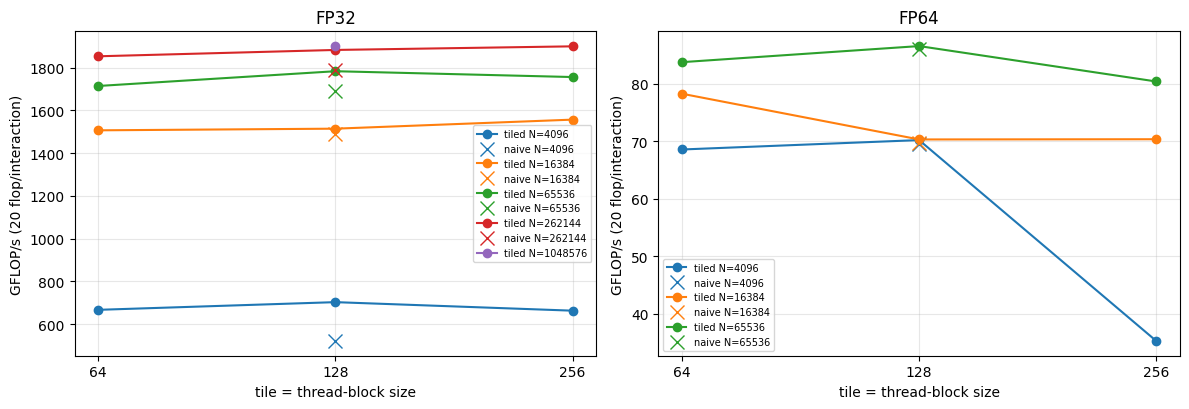

,prec,block,regs_per_thread,smem_bytes,blocks_per_SM,occupancy_pct
0,fp32,64,31,1024,16,100.0
1,fp32,128,31,2048,8,100.0
2,fp32,256,31,4096,4,100.0
3,mixed,64,38,2048,16,100.0
4,mixed,128,38,4096,8,100.0
5,mixed,256,38,8192,4,100.0
6,fp64,64,46,2048,16,100.0
7,fp64,128,46,4096,8,100.0
8,fp64,256,46,8192,4,100.0


In [25]:
import subprocess, re, pandas as pd, matplotlib.pyplot as plt
d = pd.read_csv('results/team19.csv')
d = d[d.implementation.str.contains('_ieee_u4_')]   # IEEE-sqrt, unroll 4 (the tile-size sweep)
d['prec'] = d.implementation.str.split('_').str[-1]; d['kernel'] = d.implementation.str.split('_').str[1]; d['GFLOPs'] = 20 * d.throughput / 1e9
t = d.groupby(['size', 'prec', 'kernel', 'threads_or_ranks']).GFLOPs.mean().reset_index()
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a_, prec in zip(ax, ['fp32', 'fp64']):
    for N, dd in t[(t.prec == prec) & (t.kernel == 'tiled')].groupby('size'):
        ln, = a_.plot(dd.threads_or_ranks, dd.GFLOPs, 'o-', label=f'tiled N={N}')
        nv = t[(t.prec == prec) & (t.kernel == 'naive') & (t['size'] == N)].GFLOPs
        if len(nv): a_.plot([128], nv, 'x', ms=10, c=ln.get_color(), label=f'naive N={N}')
    a_.set_xscale('log', base=2); a_.set_xticks([64, 128, 256]); a_.set_xticklabels([64, 128, 256]); a_.set_xlabel('tile = thread-block size')
    a_.set_ylabel('GFLOP/s (20 flop/interaction)'); a_.set_title(prec.upper()); a_.grid(alpha=.3); a_.legend(fontsize=7)
plt.tight_layout(); plt.savefig('results/team19_tile_chart.png', dpi=130); plt.show()
rows = []                                                          # registers / occupancy (tiled kernel, IEEE sqrt)
for prec in ['fp32', 'mixed', 'fp64']:
    for B in [64, 128, 256]:
        o = subprocess.run(['./nbody_cuda', '--variant', 'tiled', '--block', str(B), '--prec', prec, '--n', '4096', '--steps', '1',
                            '--runs', '1', '--verify', '0', '--profile', '1', '--csv', '/tmp/p.csv'], capture_output=True, text=True).stdout
        m = re.search(r'regs/thread=(\d+) static_smem=(\d+) B.*active_blocks/SM=(\d+)\s+theoretical_occupancy=([\d.]+)%', o)
        if m: rows.append(dict(prec=prec, block=B, regs_per_thread=int(m[1]), smem_bytes=int(m[2]), blocks_per_SM=int(m[3]), occupancy_pct=float(m[4])))
display(pd.DataFrame(rows))

☁️ **[RUN IN COLAB]**  **D5 – fast reciprocal square root: speed vs accuracy** (`error` = max relative first-step force error vs FP64 CPU)

In [26]:
%%bash
for P in fp32 mixed fp64; do for F in 0 1; do
  ./nbody_cuda --variant tiled --block 128 --fast $F --prec $P --n 16384 --steps 20 --csv results/team19_rsqrt.csv | grep -E "VERIFY|RESULT" | cut -c1-160
done; done

VERIFY  impl=cuda_tiled_bs128_ieee_u4_fp32  N=16384  max_rel_force_error_vs_seq_fp64 = 6.337e-06
RESULT  cuda_tiled_bs128_ieee_u4_fp32 N=16384   steps=20    par=128 total_ms=82.53+-20.66  Ginteractions/s=68.0329+-13.4749  GFLOP/s(20 flop/int)=1360.66  [5 ti
VERIFY  impl=cuda_tiled_bs128_rsqrt_u4_fp32  N=16384  max_rel_force_error_vs_seq_fp64 = 6.396e-06
RESULT  cuda_tiled_bs128_rsqrt_u4_fp32 N=16384   steps=20    par=128 total_ms=38.47+-0.87  Ginteractions/s=140.9648+-3.1570  GFLOP/s(20 flop/int)=2819.30  [5 ti
VERIFY  impl=cuda_tiled_bs128_ieee_u4_mixed  N=16384  max_rel_force_error_vs_seq_fp64 = 2.457e-07
RESULT  cuda_tiled_bs128_ieee_u4_mixed N=16384   steps=20    par=128 total_ms=782.06+-0.06  Ginteractions/s=6.8696+-0.0005  GFLOP/s(20 flop/int)=137.39  [5 time
VERIFY  impl=cuda_tiled_bs128_rsqrt_u4_mixed  N=16384  max_rel_force_error_vs_seq_fp64 = 2.685e-07
RESULT  cuda_tiled_bs128_rsqrt_u4_mixed N=16384   steps=20    par=128 total_ms=769.25+-0.17  Ginteractions/s=6.9839+-0.0017  

☁️ **[RUN IN COLAB]**  **D6 – loop unrolling** (rebuilds the kernel with unroll factor 1, 4, 8)

In [27]:
%%bash
ARCH=$(nvidia-smi --query-gpu=compute_cap --format=csv,noheader 2>/dev/null | head -1 | tr -d '.'); [ -z "$ARCH" ] && ARCH=75
for U in 1 4 8; do
  nvcc -O3 -std=c++17 -arch=sm_$ARCH -DUNROLL=$U nbody_cuda.cu -o nbody_cuda_u$U 2>&1 | grep -E "error"
  ./nbody_cuda_u$U --variant tiled --block 128 --prec fp32 --n 16384 --steps 20 --verify 0 --profile 1 --csv results/team19_unroll.csv | grep -E "PROFILE|RESULT" | cut -c1-170
done

PROFILE kernel=tiled block=128 regs/thread=27 static_smem=2048 B local_mem=0 B  active_blocks/SM=8  theoretical_occupancy=100.0%  (GPU: Tesla T4, 40 SMs)
RESULT  cuda_tiled_bs128_ieee_u1_fp32 N=16384   steps=20    par=128 total_ms=79.87+-11.96  Ginteractions/s=68.5982+-8.6035  GFLOP/s(20 flop/int)=1371.96  [5 timed runs]
PROFILE kernel=tiled block=128 regs/thread=31 static_smem=2048 B local_mem=0 B  active_blocks/SM=8  theoretical_occupancy=100.0%  (GPU: Tesla T4, 40 SMs)
RESULT  cuda_tiled_bs128_ieee_u4_fp32 N=16384   steps=20    par=128 total_ms=81.29+-22.99  Ginteractions/s=69.5900+-14.3169  GFLOP/s(20 flop/int)=1391.80  [5 timed runs]
PROFILE kernel=tiled block=128 regs/thread=30 static_smem=2048 B local_mem=0 B  active_blocks/SM=8  theoretical_occupancy=100.0%  (GPU: Tesla T4, 40 SMs)
RESULT  cuda_tiled_bs128_ieee_u8_fp32 N=16384   steps=20    par=128 total_ms=76.05+-10.51  Ginteractions/s=71.9338+-8.4533  GFLOP/s(20 flop/int)=1438.68  [5 timed runs]


☁️ **[RUN IN COLAB]**  **D7 – (optional, untested) Nsight Compute** for achieved occupancy / memory throughput. Colab often blocks hardware counters; if this prints the fallback message, use the `PROFILE` lines above.

In [28]:
%%bash
(which ncu > /dev/null && ncu --kernel-name regex:accel --launch-count 1 \
  --metrics sm__warps_active.avg.pct_of_peak_sustained_active,dram__throughput.avg.pct_of_peak_sustained_elapsed,l1tex__t_bytes.sum \
  ./nbody_cuda --variant tiled --block 128 --prec fp32 --n 16384 --steps 1 --runs 1 --verify 0 --csv /tmp/p.csv) \
  || echo "ncu not available / counters not permitted on this runtime"

==PROF== Connected to process 17921 (/content/nbody/nbody_cuda)
==PROF== Profiling "accel_tiled": 0%....50%....100% - 3 passes
CONFIG  variant=tiled prec=fp32 N=16384 steps=1 block=128 fast_rsqrt=0 unroll=4 GPU=Tesla T4
RESULT  cuda_tiled_bs128_ieee_u4_fp32 N=16384   steps=1     par=128 total_ms=5.51+-0.00  Ginteractions/s=52.9792+-0.0000  GFLOP/s(20 flop/int)=1059.58  [1 timed runs]
NOTES   threads_or_ranks column holds the CUDA thread-block size; transfer_ms = H2D + D2H copies
CSV rows appended to /tmp/p.csv
==PROF== Disconnected from process 17921
[17921] nbody_cuda@127.0.0.1
  void accel_tiled<float, float, 128, 0>(int, int, const T1 *, const T1 *, const T1 *, const T1 *, T1 *, T1 *, T1 *) (128, 1, 1)x(128, 1, 1), Context 1, Stream 7, Device 0, CC 7.5
    Section: Command line profiler metrics
    -------------------------------------------------- ----------- ------------
    Metric Name                                        Metric Unit Metric Value
    ---------------------------

☁️ **[RUN IN COLAB]**  **D8 – speedup over the CPU baseline** (same N and precision; uses Team 17's `seq` results, so run Part B first)

In [29]:
import pandas as pd, re
cpu = pd.read_csv('results/team17.csv'); gpu = pd.read_csv('results/team19.csv')
def per_step(df):
    df = df.copy(); df['steps'] = df.dataset.str.extract(r'steps(\d+)').astype(float)[0]; df['ms_step'] = df.total_ms/df.steps
    df['prec'] = df.implementation.str.split('_').str[-1]; return df
cpu, gpu = per_step(cpu), per_step(gpu)
base = cpu[cpu.implementation.str.startswith('seq_') & ~cpu.implementation.str.contains('aos')].groupby(['size','prec']).ms_step.mean()
g = gpu.groupby(['size','implementation','prec']).agg(ms_step=('ms_step','mean'), GFLOPs=('throughput', lambda v: 20*v.mean()/1e9)).reset_index()
g['speedup_vs_seq_cpu'] = g.apply(lambda r: base.get((r['size'], r.prec), float('nan'))/r.ms_step, axis=1)
pd.set_option('display.width', 220); display(g.round(3))

,size,implementation,prec,ms_step,GFLOPs,speedup_vs_seq_cpu
0,4096,cuda_naive_bs128_ieee_u4_fp32,fp32,0.677,521.666,12.033
1,4096,cuda_naive_bs128_ieee_u4_fp64,fp64,4.833,69.462,4.936
2,4096,cuda_tiled_bs128_ieee_u4_fp32,fp32,0.479,703.201,17.022
3,4096,cuda_tiled_bs128_ieee_u4_fp64,fp64,4.784,70.173,4.987
4,4096,cuda_tiled_bs256_ieee_u4_fp32,fp32,0.507,663.314,16.064
5,4096,cuda_tiled_bs256_ieee_u4_fp64,fp64,9.517,35.267,2.507
6,4096,cuda_tiled_bs64_ieee_u4_fp32,fp32,0.505,667.263,16.155
7,4096,cuda_tiled_bs64_ieee_u4_fp64,fp64,4.898,68.538,4.871
8,16384,cuda_naive_bs128_ieee_u4_fp32,fp32,3.618,1487.328,36.442
9,16384,cuda_naive_bs128_ieee_u4_fp64,fp64,77.062,69.680,5.691


☁️ **[RUN IN COLAB]**

## Part E (GPU half + final analysis) – Team 20
The CPU runs (`seq`, `openmp`, `mpi`) are already in `acc/` from your PC. Here the **CUDA** runs (`cuda` = tiled/IEEE sqrt, `cuda_rsqrt` = fast rsqrt) are added in FP64/FP32/mixed – **same N = 4096 and 10,000 steps** – and then everything is analysed together.

☁️ **[RUN IN COLAB]**  **E1 – helper scripts**

In [30]:
%%writefile team20_run.py
#!/usr/bin/env python3
"""Team 20 : run every platform (seq, OpenMP, MPI, CUDA) in FP64 / FP32 / mixed for the accuracy study.
Each run simulates --steps steps and samples energy + positions every --every steps.
Outputs (per run, in --out):  <platform>_<prec>_energy.csv, <platform>_<prec>_traj.bin, <platform>_<prec>_results.csv"""
import argparse, os, subprocess, sys, shutil, time

ap = argparse.ArgumentParser()
ap.add_argument('--n', type=int, default=1024, help='particles (keep <=2048 on Colab for 10,000 steps)')
ap.add_argument('--steps', type=int, default=10000)
ap.add_argument('--every', type=int, default=100, help='energy/trajectory sampling interval (steps)')
ap.add_argument('--threads', type=int, default=os.cpu_count() or 2)
ap.add_argument('--ranks', type=int, default=2, help='MPI ranks (N must be divisible by it)')
ap.add_argument('--bin', default='.')
ap.add_argument('--out', default='acc')
ap.add_argument('--precs', default='fp64,fp32,mixed')
ap.add_argument('--platforms', default='seq,openmp,mpi,cuda,cuda_rsqrt',
                help='comma list from: seq,openmp,mpi,cuda,cuda_rsqrt')
a = ap.parse_args()

os.makedirs(a.out, exist_ok=True)
env = dict(os.environ, OMPI_ALLOW_RUN_AS_ROOT='1', OMPI_ALLOW_RUN_AS_ROOT_CONFIRM='1',
           OMPI_MCA_rmaps_base_oversubscribe='1', OMPI_MCA_btl_vader_single_copy_mechanism='none')
B = a.bin
def cmd_for(plat, prec):
    if plat == 'seq':    return [f'{B}/nbody_smp', '--variant', 'seq', '--threads', '1', '--prec', prec]
    if plat == 'openmp': return [f'{B}/nbody_smp', '--variant', 'omp_full', '--threads', str(a.threads), '--prec', prec]
    if plat == 'mpi':    return ['mpirun', '-np', str(a.ranks), f'{B}/nbody_mpi', '--variant', 'ring', '--prec', prec]
    if plat == 'cuda':   return [f'{B}/nbody_cuda', '--variant', 'tiled', '--block', '128', '--fast', '0', '--prec', prec]
    if plat == 'cuda_rsqrt': return [f'{B}/nbody_cuda', '--variant', 'tiled', '--block', '128', '--fast', '1', '--prec', prec]
    raise SystemExit('unknown platform ' + plat)

# the sequential FP64 run is the reference for trajectory errors -> run it first
plats = [p for p in a.platforms.split(',') if p]
if 'seq' in plats: plats.remove('seq')
plats = ['seq'] + plats
precs = a.precs.split(',')
t_all = time.time()
for plat in plats:
    if plat.startswith('cuda') and not os.path.exists(f'{B}/nbody_cuda'):
        print(f'[skip] {plat}: ./nbody_cuda not built (needs a GPU runtime)'); continue
    for prec in precs:
        tag = f'{plat}_{prec}'
        res = f'{a.out}/{tag}_results.csv'
        if os.path.exists(res): os.remove(res)
        cmd = cmd_for(plat, prec) + ['--n', str(a.n), '--steps', str(a.steps), '--energy-every', str(a.every),
                                      '--out', f'{a.out}/{tag}', '--csv', res]
        t0 = time.time()
        p = subprocess.run(cmd, env=env, capture_output=True, text=True)
        if p.returncode != 0:
            print(f'[FAILED] {tag}\n{p.stdout}\n{p.stderr}'); sys.exit(1)
        line = [l for l in p.stdout.splitlines() if l.startswith(('VERIFY', 'ACCURACY'))]
        print(f'[{time.time()-t0:6.1f}s] {tag:18s}', ' | '.join(l.split('impl=')[-1] if l.startswith('ACCURACY') else l.split('=')[-1].strip() for l in line))
print(f'all runs finished in {time.time()-t_all:.0f}s -> {a.out}/')

Overwriting team20_run.py


In [31]:
%%writefile team20_analyze.py
#!/usr/bin/env python3
"""Team 20 : energy drift, trajectory error vs time, accuracy-vs-speed (Pareto) chart,
CPU-vs-GPU particle comparison, recommendation table."""
import argparse, glob, os
import numpy as np, pandas as pd
import matplotlib; matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

ap = argparse.ArgumentParser()
ap.add_argument('--dir', default='acc')
ap.add_argument('--tol', type=float, default=1e-5, help='max allowed |dE/E0| for the recommended configuration')
ap.add_argument('--pos-tol', type=float, default=1e-6, help='max allowed final RMS position error vs the reference')
ap.add_argument('--ref', default='seq_fp64', help='reference run for trajectory error')
a = ap.parse_args()

COL = {'seq': 'k', 'openmp': 'tab:blue', 'mpi': 'tab:green', 'cuda': 'tab:red', 'cuda_rsqrt': 'tab:orange'}
LS  = {'fp64': '-', 'fp32': '--', 'mixed': ':'}
MK  = {'fp64': 'o', 'fp32': 's', 'mixed': '^'}
def split(tag): plat, prec = tag.rsplit('_', 1); return plat, prec

def read_traj(f):                                   # file layout: int64 n, int64 nsnap, then nsnap*(x[n],y[n],z[n]) doubles
    with open(f, 'rb') as fh:
        n, ns = np.fromfile(fh, dtype=np.int64, count=2)
        return np.fromfile(fh, dtype=np.float64).reshape(ns, 3, n)

tags = sorted(os.path.basename(f)[:-len('_energy.csv')] for f in glob.glob(f'{a.dir}/*_energy.csv'))
if not tags: raise SystemExit(f'no *_energy.csv in {a.dir}/ - run team20_run.py first')
E = {t: pd.read_csv(f'{a.dir}/{t}_energy.csv') for t in tags}
T = {t: read_traj(f'{a.dir}/{t}_traj.bin') for t in tags}
if a.ref not in T: raise SystemExit(f'reference run {a.ref} missing')
ref = T[a.ref]
if len({T[t].shape for t in tags}) != 1:
    raise SystemExit('runs have different N or step counts (local CPU runs and Colab GPU runs must use the same --n and --steps): '
                     + str({t: T[t].shape for t in tags}))

# ---- 1. energy: (left) drift from its own start, (right) difference from the FP64 reference run ----
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
E0ref = abs(E[a.ref].etot.iloc[0])
for t in tags:
    p, q = split(t); d = E[t]
    axs[0].plot(d.time[1:], np.maximum(np.abs(d.rel_drift[1:]), 1e-17), color=COL.get(p, 'gray'), ls=LS.get(q, '-'), label=t)
    if t != a.ref:
        diff = np.abs(d.etot - E[a.ref].etot) / E0ref
        axs[1].plot(d.time, np.maximum(diff, 1e-17), color=COL.get(p, 'gray'), ls=LS.get(q, '-'), label=t)
axs[0].set_ylabel('|E - E0| / |E0|');                axs[0].set_title('Energy drift (integrator + round-off)')
axs[1].set_ylabel('|E - E_ref| / |E0|');             axs[1].set_title('Energy difference from ' + a.ref + ' (shows round-off)')
for ax in axs:
    ax.set_yscale('log'); ax.set_xlabel('simulation time'); ax.grid(alpha=.3, which='both'); ax.legend(ncol=2, fontsize=6)
fig.tight_layout(); fig.savefig(f'{a.dir}/plot_energy_drift.png', dpi=150)

# ---- 2. trajectory error vs reference ----
def traj_err(t):
    d = T[t] - ref                                 # (snapshots, 3, n)
    dist = np.sqrt((d ** 2).sum(axis=1))           # per-particle distance
    return np.sqrt((dist ** 2).mean(axis=1)), dist.max(axis=1)
fig, ax = plt.subplots(figsize=(9, 5))
for t in tags:
    if t == a.ref: continue
    p, q = split(t); rms, _ = traj_err(t)
    ax.plot(E[t].time, np.maximum(rms, 1e-17), color=COL.get(p, 'gray'), ls=LS.get(q, '-'), label=t)
ax.set_yscale('log'); ax.set_xlabel('simulation time'); ax.set_ylabel('RMS position error vs ' + a.ref)
ax.set_title('Trajectory error vs FP64 sequential reference'); ax.grid(alpha=.3, which='both'); ax.legend(ncol=2, fontsize=7)
fig.tight_layout(); fig.savefig(f'{a.dir}/plot_trajectory_error.png', dpi=150)

# ---- 3. summary table + Pareto ----
rows = []
for t in tags:
    p, q = split(t); r = pd.read_csv(f'{a.dir}/{t}_results.csv').iloc[0]
    rms, mx = traj_err(t); d = E[t]
    rows.append(dict(tag=t, platform=p, precision=q, implementation=r.implementation, Ginteractions_per_s=r.throughput / 1e9,
                     max_abs_energy_drift=np.abs(d.rel_drift).max(), final_energy_drift=d.rel_drift.iloc[-1],
                     final_rms_pos_error=rms[-1], final_max_pos_error=mx[-1],
                     first_step_force_error=(float(r.error) if pd.notna(r.error) else np.nan)))
S = pd.DataFrame(rows)

def pareto(df, xcol, ycol):                         # maximise x (speed), minimise y (error)
    keep = []
    for i, r in df.iterrows():
        dom = ((df[xcol] >= r[xcol]) & (df[ycol] <= r[ycol]) & ((df[xcol] > r[xcol]) | (df[ycol] < r[ycol]))).any()
        keep.append(not dom)
    return df[keep]

fig, axs = plt.subplots(1, 2, figsize=(13, 5))
for ax, ycol, yl in [(axs[0], 'max_abs_energy_drift', 'max |dE/E0| over the run'), (axs[1], 'final_rms_pos_error', 'final RMS position error vs ' + a.ref)]:
    for _, r in S.iterrows():
        ax.scatter(r.Ginteractions_per_s, max(r[ycol], 1e-17), c=COL.get(r.platform, 'gray'), marker=MK.get(r.precision, 'o'), s=70)
        ax.annotate(r.tag, (r.Ginteractions_per_s, max(r[ycol], 1e-17)), fontsize=6, xytext=(3, 3), textcoords='offset points')
    pf = pareto(S.assign(**{ycol: S[ycol].clip(lower=1e-17)}), 'Ginteractions_per_s', ycol).sort_values('Ginteractions_per_s')
    ax.step(pf.Ginteractions_per_s, pf[ycol].clip(lower=1e-17), where='post', c='gray', lw=1, alpha=.6)
    ax.set_xscale('log'); ax.set_yscale('log'); ax.set_xlabel('speed  (10^9 pair interactions / s)'); ax.set_ylabel(yl); ax.grid(alpha=.3, which='both')
h = [Line2D([], [], marker='o', ls='', color=c, label=p) for p, c in COL.items() if p in set(S.platform)] + \
    [Line2D([], [], marker=m, ls='', color='gray', label=q) for q, m in MK.items()]
axs[1].legend(handles=h, fontsize=8, loc='lower right')
axs[0].set_title('Accuracy vs performance (energy)'); axs[1].set_title('Accuracy vs performance (trajectory)')
fig.tight_layout(); fig.savefig(f'{a.dir}/plot_pareto.png', dpi=150)

# ---- 4. the particles themselves: CPU reference vs GPU ----
# There are NOT separate "CPU particles" and "GPU particles": every platform simulates the SAME N particles
# (same seed -> same initial positions).  Only the hardware / precision doing the arithmetic differs.
# So the CPU and GPU dots should lie on top of each other; the real difference is tiny and is shown as a histogram.
dev = 'cuda' if 'cuda_fp32' in T else 'openmp'      # falls back to OpenMP on a CPU-only runtime
print(f'initial-position check vs {a.ref} (should be ~0 for fp64, ~1e-8 for fp32 because positions are stored as float):')
for t in tags: print(f'   {t:18s} max |x0 - x0_ref| = {np.abs(T[t][0] - ref[0]).max():.2e}')
fig, axs = plt.subplots(1, 3, figsize=(16, 5))
axs[0].scatter(ref[0, 0], ref[0, 1], s=3, c='gray')
axs[0].set_title(f'initial positions (N={ref.shape[2]}, x-y view)\nidentical on every platform')
axs[1].scatter(ref[-1, 0], ref[-1, 1], s=30, facecolors='none', edgecolors='k', lw=.6, label=a.ref + '  (CPU reference)')
axs[1].scatter(T[dev + '_fp32'][-1, 0], T[dev + '_fp32'][-1, 1], s=3, c='r', label=dev + '_fp32  (' + ('GPU' if dev == 'cuda' else 'CPU') + ')')
axs[1].set_title('final positions, both overlaid\n(red dots sit inside the black circles)'); axs[1].legend(fontsize=7)
bins = np.logspace(-16, -2, 36)
for q, c in [('fp64', 'tab:blue'), ('mixed', 'tab:green'), ('fp32', 'tab:red')]:
    t = f'{dev}_{q}'
    if t in T: axs[2].hist(np.clip(np.sqrt(((T[t][-1] - ref[-1]) ** 2).sum(axis=0)), 1e-16, None), bins=bins, alpha=.6, color=c, label=t)
axs[2].set_xscale('log'); axs[2].set_xlabel('final position error of one particle vs ' + a.ref); axs[2].set_ylabel('number of particles')
axs[2].set_title('how far each particle is from the CPU reference'); axs[2].legend(fontsize=8)
for ax in axs[:2]: ax.set_xlabel('x'); ax.set_ylabel('y'); ax.set_aspect('equal')
fig.tight_layout(); fig.savefig(f'{a.dir}/plot_particles.png', dpi=150)

# ---- 5. recommendation: fastest precision per platform that meets BOTH tolerances ----
rec = []
for plat, g in S.groupby('platform'):
    ok = g[(g.max_abs_energy_drift <= a.tol) & (g.final_rms_pos_error <= a.pos_tol)]
    pick = ok.sort_values('Ginteractions_per_s', ascending=False).iloc[0] if len(ok) else g.sort_values('final_rms_pos_error').iloc[0]
    rec.append(dict(platform=plat, recommended_precision=pick.precision, Ginteractions_per_s=pick.Ginteractions_per_s,
                    max_abs_energy_drift=pick.max_abs_energy_drift, final_rms_pos_error=pick.final_rms_pos_error,
                    meets_tolerances=bool(len(ok))))
R = pd.DataFrame(rec)
S.to_csv(f'{a.dir}/summary_all_runs.csv', index=False); R.to_csv(f'{a.dir}/summary_recommendation.csv', index=False)
pd.set_option('display.width', 220); pd.set_option('display.float_format', lambda v: f'{v:.3e}')
print(S.drop(columns=['tag']).to_string(index=False))
print(f'\nRecommended configuration per platform (|dE/E0| <= {a.tol:g} and final RMS position error <= {a.pos_tol:g}):')
print(R.to_string(index=False)); print(f'\nSaved plots + summaries in {a.dir}/')


Overwriting team20_analyze.py


☁️ **[RUN IN COLAB]**  **E2 – GPU accuracy runs (10,000 steps)** – takes ~3 min

In [33]:
import os

os.chmod("/content/nbody/nbody_smp", 0o755)

print("Executable permission granted!")

Executable permission granted!


In [34]:
import os
import stat

path = "/content/nbody/nbody_smp"

print("File exists:", os.path.isfile(path))
print("Executable:", os.access(path, os.X_OK))
print("Permissions:", oct(os.stat(path).st_mode & 0o777))

File exists: True
Executable: True
Permissions: 0o755


In [35]:
%%bash
python3 team20_run.py --n 4096 --steps 10000 --every 100 --platforms cuda,cuda_rsqrt --out acc

[ 308.5s] seq_fp64           0.000e+00 | seq_fp64 N=4096 steps=10000  advance_time=306852.5 ms  Ginteractions/s=0.5468  max|dE/E0|=1.254e-06
[ 124.2s] seq_fp32           5.820e-07 | seq_fp32 N=4096 steps=10000  advance_time=122642.3 ms  Ginteractions/s=1.3680  max|dE/E0|=1.185e-06
[ 400.7s] seq_mixed          2.238e-07 | seq_mixed N=4096 steps=10000  advance_time=399064.4 ms  Ginteractions/s=0.4204  max|dE/E0|=1.256e-06
[  50.3s] cuda_fp64          8.042e-16 | cuda_tiled_bs128_ieee_u4_fp64 N=4096 steps=10000  advance_time=47775.3 ms  Ginteractions/s=3.5117  max|dE/E0|=1.254e-06
[   7.0s] cuda_fp32          3.453e-06 | cuda_tiled_bs128_ieee_u4_fp32 N=4096 steps=10000  advance_time=4770.7 ms  Ginteractions/s=35.1668  max|dE/E0|=1.216e-06
[  27.2s] cuda_mixed         2.238e-07 | cuda_tiled_bs128_ieee_u4_mixed N=4096 steps=10000  advance_time=24811.8 ms  Ginteractions/s=6.7618  max|dE/E0|=1.256e-06
[  36.1s] cuda_rsqrt_fp64    1.133e-15 | cuda_tiled_bs128_rsqrt_u4_fp64 N=4096 steps=10000  

☁️ **[RUN IN COLAB]**  **E3 – final analysis of ALL platforms (CPU from your PC + GPU)** – energy-drift plot, trajectory error vs time, accuracy-vs-speed (Pareto) chart, CPU-vs-GPU particle plot, and the recommended configuration per platform (fastest precision with max |ΔE/E₀| ≤ `--tol` **and** final RMS position error ≤ `--pos-tol`).

In [36]:
%%bash
python3 team20_analyze.py --dir acc --tol 1e-5 --pos-tol 1e-6

initial-position check vs seq_fp64 (should be ~0 for fp64, ~1e-8 for fp32 because positions are stored as float):
   cuda_fp32          max |x0 - x0_ref| = 2.98e-08
   cuda_fp64          max |x0 - x0_ref| = 0.00e+00
   cuda_mixed         max |x0 - x0_ref| = 0.00e+00
   cuda_rsqrt_fp32    max |x0 - x0_ref| = 2.98e-08
   cuda_rsqrt_fp64    max |x0 - x0_ref| = 0.00e+00
   cuda_rsqrt_mixed   max |x0 - x0_ref| = 0.00e+00
   mpi_fp32           max |x0 - x0_ref| = 2.98e-08
   mpi_fp64           max |x0 - x0_ref| = 0.00e+00
   mpi_mixed          max |x0 - x0_ref| = 0.00e+00
   openmp_fp32        max |x0 - x0_ref| = 2.98e-08
   openmp_fp64        max |x0 - x0_ref| = 0.00e+00
   openmp_mixed       max |x0 - x0_ref| = 0.00e+00
   seq_fp32           max |x0 - x0_ref| = 2.98e-08
   seq_fp64           max |x0 - x0_ref| = 0.00e+00
   seq_mixed          max |x0 - x0_ref| = 0.00e+00
  platform precision                  implementation  Ginteractions_per_s  max_abs_energy_drift  final_energy_drift  fina

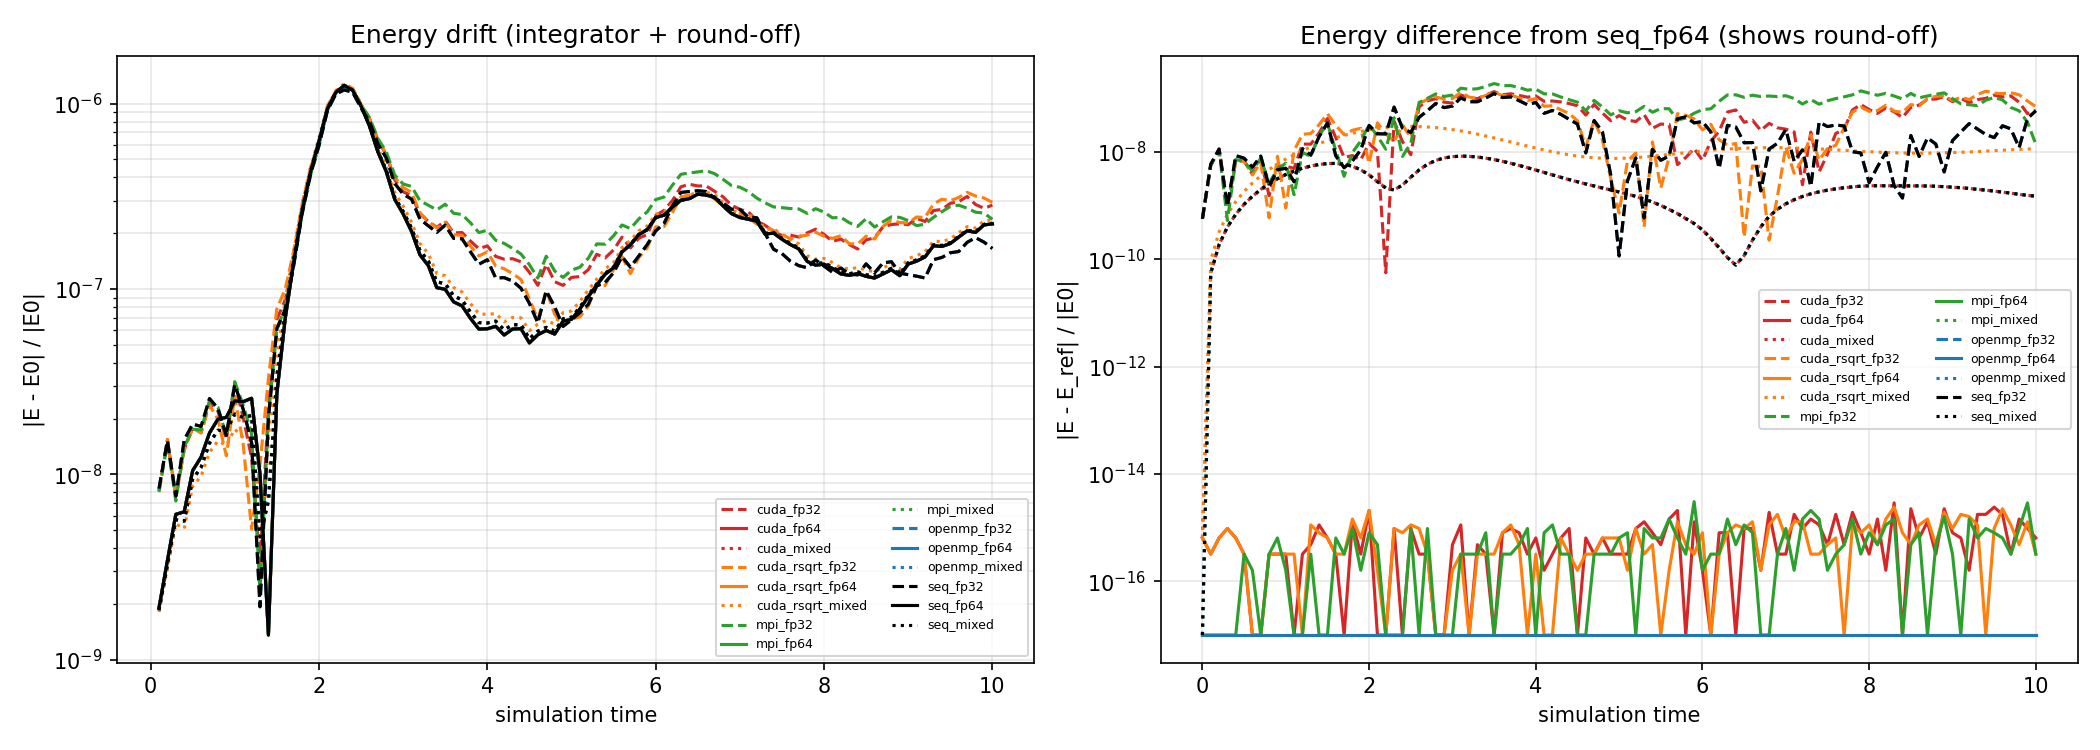

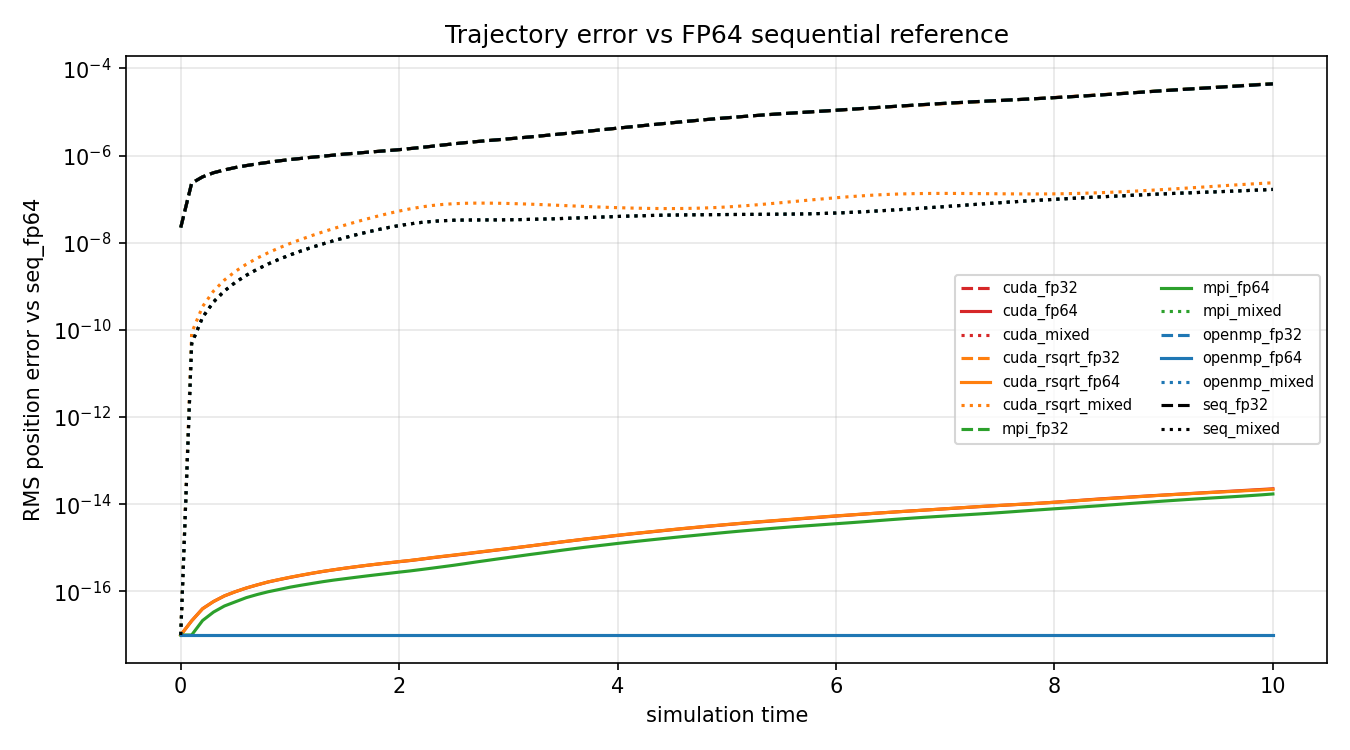

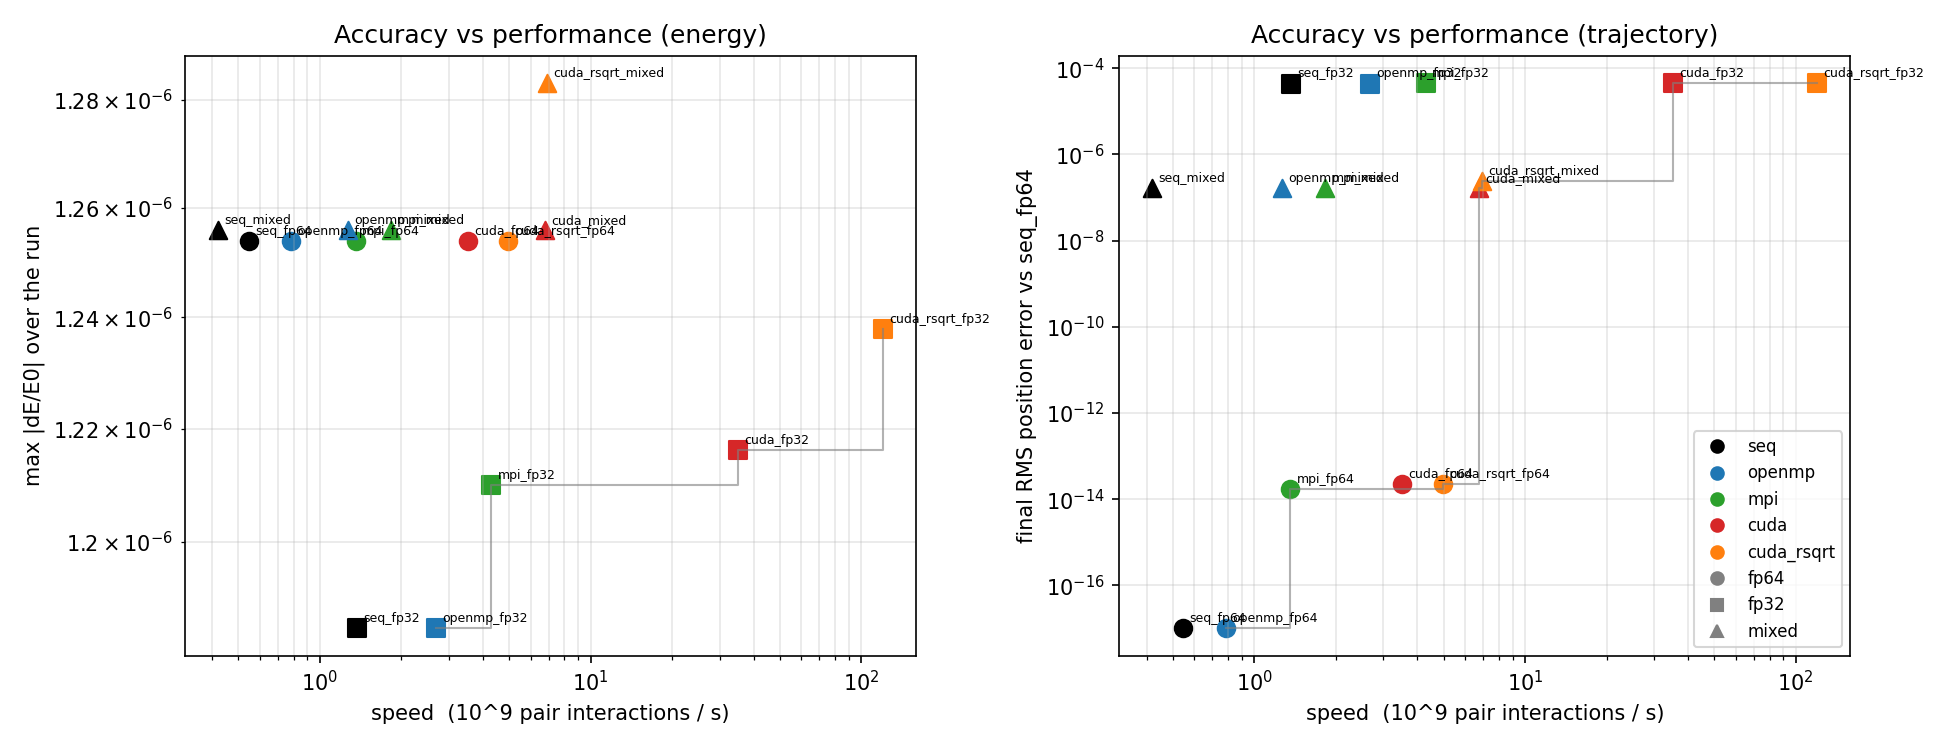

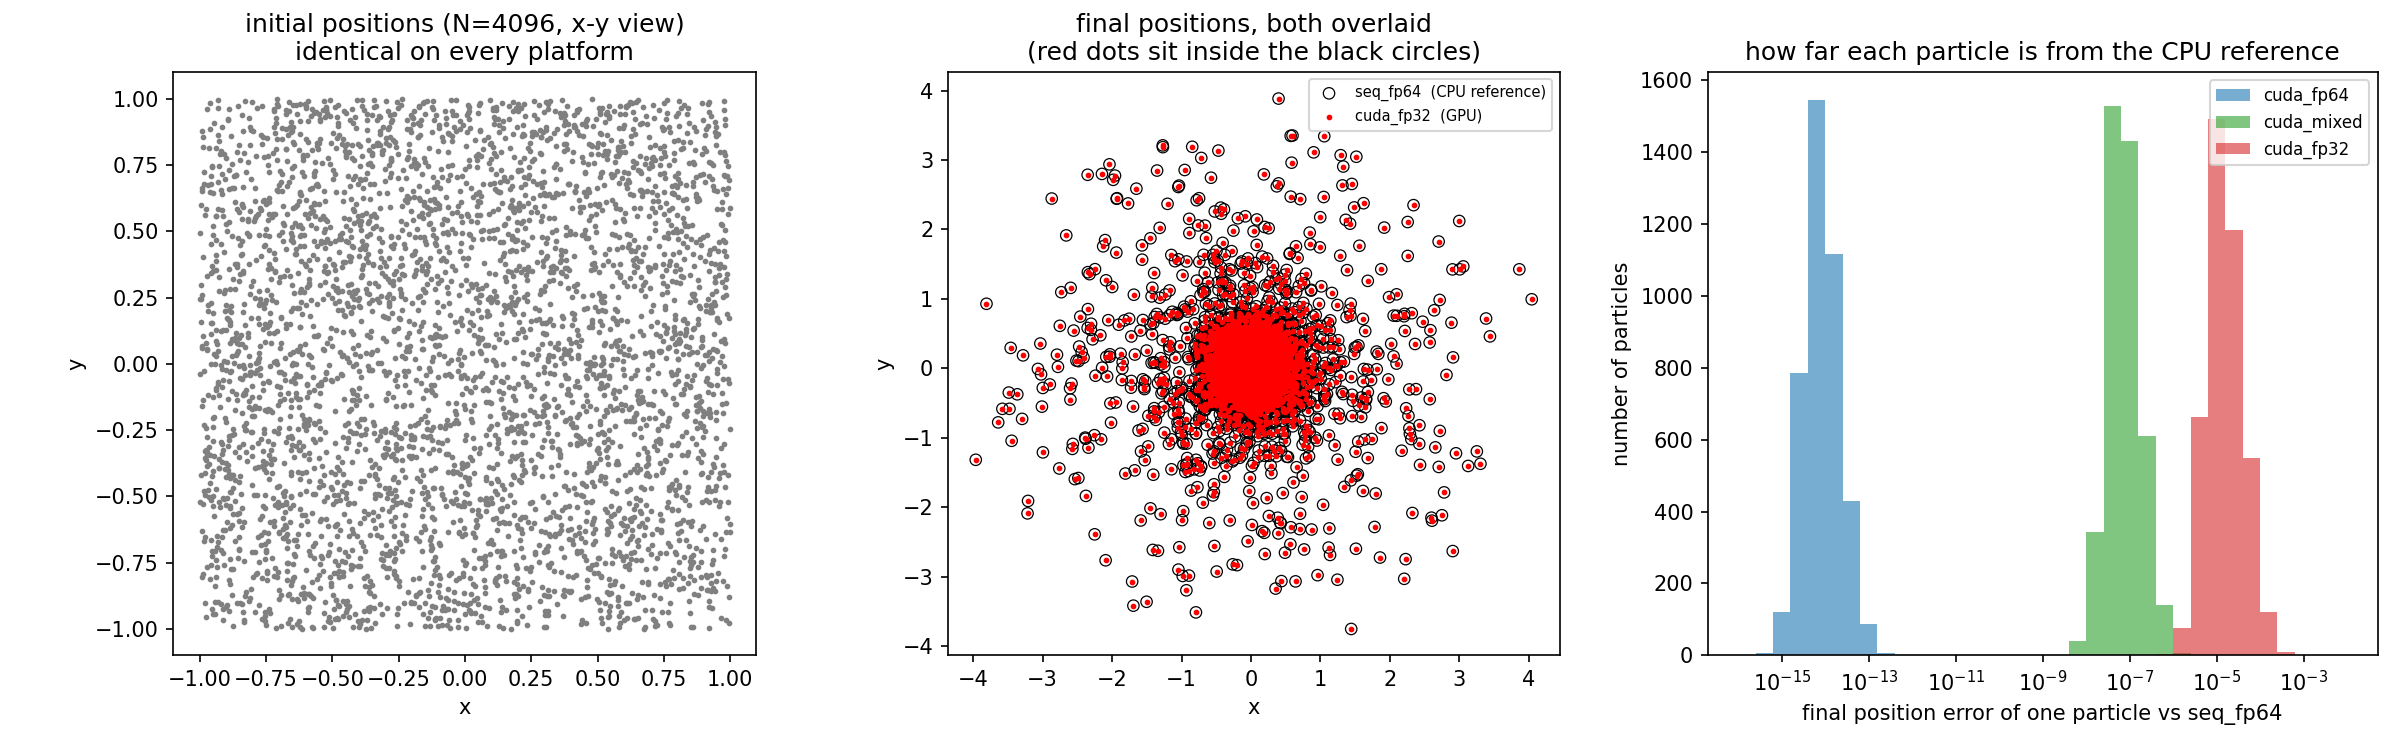

In [37]:
from IPython.display import Image, display
for f in ['plot_energy_drift', 'plot_trajectory_error', 'plot_pareto', 'plot_particles']: display(Image(f'acc/{f}.png'))

**How to read the results (for the discussion section)**
* *CPU vs GPU particles:* there is only **one** set of particles. `plot_particles.png` shows the CPU reference and the GPU result on top of each other (they coincide) and a histogram of each particle's final distance from the CPU reference – that histogram is where the CPU/GPU difference is visible.
* *Energy drift* mostly measures the **integrator** (velocity-Verlet with dt = 1e-3 gives ≈ 1e-6 relative energy error) – so FP32 and mixed can look as good as FP64 on this metric. Lower the time step (edit `DT` in `nbody_common.hpp` and rebuild everything) if you want round-off to show up in the energy.
* *Trajectory error* is where precision shows: gravity is chaotic, so any perturbation (FP32 round-off, or even a different summation order) grows roughly exponentially with time. Expect FP64 platforms to agree to ~1e-13 or better for a long time, mixed ≈ 1e-8…1e-6, FP32 ≈ 1e-6 and growing – compare *statistics* (energy) as well as individual orbits.
* Speed: FP32 gives the biggest speedup on CPU (SIMD width ×2) and on consumer/T4 GPUs (FP64 is 1/32 rate); `mixed` keeps FP64 state but cheap FP32 pair math.

### Team 20 - report outline (task 5: introduction, comparison, discussion)
Fill the `<…>` from `acc/summary_all_runs.csv`, `acc/summary_recommendation.csv` and the plots above.

**1. Introduction.** N-body gravity (softened, G = 1, ε = 0.05), velocity-Verlet, dt = 1e-3, N = `<N>`, 10,000 steps. Three precision modes: *fp64*, *fp32*, *mixed* (FP32 pair force, FP64 state and accumulation). Platforms: sequential, OpenMP, MPI (ring), CUDA (tiled, IEEE sqrt and fast `rsqrt`). Every platform simulates the **same** particles (same seed); the reference is `seq_fp64`.

**2. Comparison.**
* *Energy:* max |ΔE/E₀| = `<…>` for every run - set by the integrator, not by the precision (left panel of the energy plot). The right panel (energy difference from the reference) is where the precision shows.
* *Trajectories:* final RMS position error – fp64 platforms ≈ `<1e-13>`, mixed ≈ `<1e-7>`, fp32 ≈ `<1e-4>`; errors grow with time (chaotic system). `cuda_rsqrt` vs `cuda`: `<…>`.
* *Speed:* fp32 / fp64 speedup on CPU = `<…>`, on GPU = `<…>` (T4 FP64 is 1/32 rate). Mixed = `<…>`. Note: at N = 4096 the GPU is still under-used compared with larger N, see D8 and D4.
* *Pareto chart:* the points on the grey staircase are the best accuracy-for-speed choices: `<list>`.

**3. Discussion / recommendation.** Recommended precision per platform (table above): `<seq: …, OpenMP: …, MPI: …, CUDA: …>`. Reasoning: `<accuracy needed vs speed gained>`. Limits of the study: CPU results come from your PC (`<CPU model, cores>`) and GPU results from a Colab T4 - different machines, so speeds are compared as 'what each platform can do', not as a like-for-like race; one N, one initial condition; energy conservation does not prove an individual orbit is right.


☁️ **[RUN IN COLAB]**

### Download everything

In [38]:
import shutil
shutil.make_archive('/content/colab_results', 'zip', '/content/nbody', 'results')
shutil.make_archive('/content/colab_acc', 'zip', '/content/nbody', 'acc')
from google.colab import files
files.download('/content/colab_results.zip'); files.download('/content/colab_acc.zip')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>